# Phase 4d: Step 3 — Spatial Analysis (H3)

**Date:** 2026-11-03  
**Driver:** `code/R/04d_step3_spatial.R --date 2026-11-03`  
**Results:** `results/2026-11-03/h3/`

---

## What is spatial analysis?

H3 asks whether AI data-center concentration clusters spatially and whether neighbor states' AI activity spills over into own renewable outcomes.

**Three models:**

1. **Moran's I** — tests whether the spatial autocorrelation of AI or outcomes is higher than chance. Null: random spatial arrangement.

2. **SLX** (Spatial Lag of X) — the memo's fallback and the clustered-SE companion to the SDM:  
   `Y = b1·AI(t-1) + θ1·W·AI(t-1) + b·X + θ·W·X + μ_i + λ_t`  
   Only clustered-SE model; direct (b1) and neighbor (θ1) effects separable; total = b1+θ1 with delta-method SE.

3. **SDM** (Spatial Durbin Model) — adds spatial lag of Y (ρ·W·Y) to the SLX:  
   `Y = ρ·WY + b1·AI(t-1) + θ1·W·AI(t-1) + b·X + θ·W·X + μ_i + λ_t`  
   Estimated via ML (SDPDmod::SDPDm). The SDM indirect effect is the main H3 test.  
   Direct/indirect/total impacts from `impactsSDPDm()` account for the feedback loop in ρ·WY.

**W matrices:**
- Main: **invdist-50** (`W_inverse_distance_rowstd.csv`, all 50 states, row-standardized)
- Checks: **invdist-48** (drop AK+HI, re-normalized) and **border-48** (contiguity, row-standardized)

**Controls:** ctrl4 = ln_gdp_pc + manuf_share + price_c_kwh + pop_growth.  
**SLX SEs:** clustered by state (CRV1). **SDM SEs:** asymptotic ML (not clustered).  
**Sample:** 50 states × 11 years = 550 obs (invdist-50); 48 states × 11 years = 528 (48-state W checks).

**SDPDm notes:**
- `LYtrans=TRUE` applies Lee-Yu (2010) bias correction for two-way FE panel (main result when converged).
- `LYtrans=FALSE` = uncorrected ML (shown beside; used for splm cross-check).
- `demn=FALSE`: `effect='twoways'` handles FE removal internally; demn is for explicit Lee-Yu demeaning (not needed here).
- **Convergence flag:** SDPDmod LYtrans=TRUE gave rho > 1 for ln_ec and ln_ee with invdist W (rho ≈ 4.8–6.1). These are outside the valid interval (1/λ_min, 1) = (−4.74, 1) for invdist-50 and indicate a numerical convergence failure. Use LYtrans=FALSE for those outcomes. renew_share converges correctly (rho=0.776).
- SEs are asymptotic ML; compare b1 and θ1 with SLX (which has clustered SEs).

**AI measure:** `ai_dc_per1000` is **private data-center jobs per 1,000 workers**: QCEW NAICS 518210, private ownership only, over all covered jobs, times 1,000. "AI" in this notebook is shorthand for this measure. Government 518210 rows exist but are left out of the main measure; see `EXPERIMENTS.md` §0 item 24.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image

DATE = '2026-11-03'
H3   = f'../results/{DATE}/h3/'
FIGS = f'../results/{DATE}/figures/'

moran  = pd.read_csv(H3 + 'h3_moran.csv')
lm     = pd.read_csv(H3 + 'h3_lm_tests.csv')
slx    = pd.read_csv(H3 + 'h3_slx.csv')
sdm_c  = pd.read_csv(H3 + 'h3_sdm_core.csv')
sdm_i  = pd.read_csv(H3 + 'h3_sdm_impacts.csv')
splm_c = pd.read_csv(H3 + 'h3_splm_check.csv')
print('Moran rows:', len(moran))
print('SLX rows:', len(slx))
print('SDM core rows:', len(sdm_c))
print('SDM impacts rows:', len(sdm_i))

Moran rows: 231
SLX rows: 9
SDM core rows: 12
SDM impacts rows: 12


---
## 1. Moran's I — spatial clustering (H3a)

Null: random spatial arrangement. `alternative='greater'`: tests for positive spatial autocorrelation.  
999 permutations, p-value = proportion of simulated I ≥ observed I.

In [2]:
# renew_share by year, invdist-50
rs_i50 = moran[(moran.variable=='renew_share') & (moran.W_version=='invdist50') & (moran.type=='raw')]
rs_i50 = rs_i50[['year','moran_I','p_value']].sort_values('year')
rs_i50.columns = ['Year','Moran I','p']
rs_i50 = rs_i50.round({'Moran I':4, 'p':3})
print('renew_share Moran I, invdist-50:')
display(rs_i50.set_index('Year'))

renew_share Moran I, invdist-50:


,Moran I,p
Year,,
2015,0.0941,0.001
2016,0.1112,0.002
2017,0.1202,0.001
2018,0.1161,0.001
2019,0.1090,0.001
2020,0.1151,0.002
2021,0.1211,0.001
2022,0.1331,0.001
2023,0.1336,0.001


In [3]:
# AI lag1 Moran I, all W
ai_m = moran[(moran.variable=='ai_dc_per1000_lag1') & (moran.type=='raw')]
ai_piv = ai_m.pivot_table(index='year', columns='W_version', values='moran_I').round(4)
print('AI lag1 Moran I by year and W:')
display(ai_piv)

AI lag1 Moran I by year and W:


W_version,border48,invdist48,invdist50
year,,,
2015,-0.0476,-0.0516,-0.0456
2016,-0.0571,-0.0532,-0.0473
2017,-0.0636,-0.0425,-0.0386
2018,-0.0199,-0.0330,-0.0337
2019,0.0276,-0.0214,-0.0239
2020,0.0265,-0.0160,-0.0201
2021,-0.0081,-0.0276,-0.0297
2022,0.0063,-0.0232,-0.0257
2023,0.0156,-0.0210,-0.0242


In [4]:
# Residual Moran I (renew_share TWFE residuals)
res_m = moran[(moran.variable=='resid_renew_share') & (moran.type=='resid')]
res_piv = res_m.pivot_table(index='year', columns='W_version', values=['moran_I','p_value']).round(4)
print('Residual Moran I (renew_share TWFE residuals):')
display(res_piv)

Residual Moran I (renew_share TWFE residuals):


moran_I                      p_value                    
W_version border48 invdist48 invdist50 border48 invdist48 invdist50
year                                                               
2015        0.3095    0.1123    0.1099    0.003     0.001     0.001
2016        0.2877    0.0565    0.0550    0.002     0.007     0.011
2017        0.2633    0.0369    0.0342    0.001     0.026     0.031
2018        0.3444    0.0703    0.0679    0.001     0.002     0.001
2019        0.1556    0.0453    0.0413    0.019     0.013     0.012
2020        0.1271    0.0206    0.0198    0.066     0.058     0.055
2021        0.3149    0.0440    0.0427    0.001     0.022     0.017
2022        0.3425    0.0914    0.0873    0.001     0.002     0.001
2023        0.2358    0.0259    0.0240    0.001     0.030     0.046
2024        0.2772    0.0619    0.0607    0.002     0.004     0.006
2025        0.3158    0.0941    0.0879    0.001     0.001     0.001

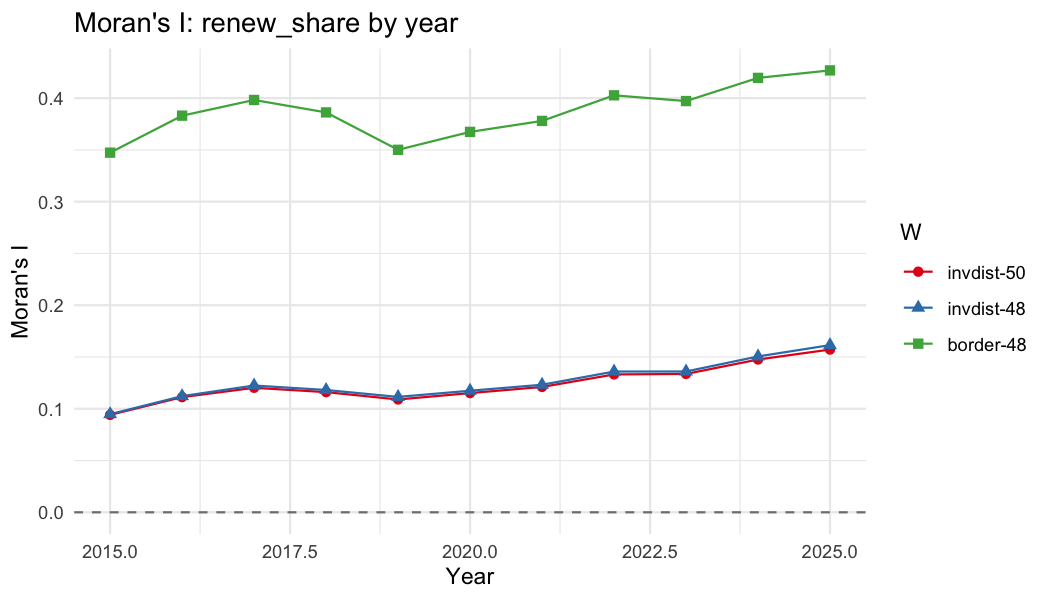

In [5]:
Image(FIGS + 'h3_moran_time_renew_share.png')

### Reading (Moran's I)

**renew_share clustering is significant in every year (p ≤ 0.002, invdist-50)**, rising from I=0.094 in 2015 to I=0.157 in 2025. States with high renewable shares cluster near each other (New England, PNW, Mountain West) and low-share states cluster in the Southeast — this trend is strengthening over time.

**AI lag1 is also positively clustered** (invdist-50), with I peaking in 2021–2022 before stabilizing. This provides motivation for a spatial model.

**Residual Moran's I:** After two-way FE and AI(t-1), renew_share residuals still cluster: I = 0.02–0.11, with p < 0.05 in 10 of 11 years (2020: p = 0.055). Two-way FE does not absorb the spatial pattern, so clustered-by-state SEs may be too small. 4e check A8 (Conley SEs) tests this. The SDM adds a spatial lag of Y to test for spillover beyond what two-way FE captures.

---
## 2. LM pre-tests (optional)

LM-lag (lml), LM-error (lme), and robust versions. Two-way FE model, invdist-50 listw.

In [6]:
lm_piv = lm.pivot_table(index='outcome', columns='test', values=['statistic','p_value'])
lm_piv = lm_piv.round(3)
print('LM pre-tests (invdist-50):')
display(lm_piv)

LM pre-tests (invdist-50):


p_value                      statistic                       
test            lme    lml   rlme   rlml       lme    lml    rlme    rlml
outcome                                                                  
ln_ec         0.159  0.312  0.131  0.251     1.980  1.024   2.276   1.320
ln_ee         0.005  0.877  0.000  0.000     7.711  0.024  46.886  39.198
renew_share   0.599  0.619  0.827  0.892     0.277  0.247   0.048   0.018

### Reading (LM tests)

- **ln_ec, renew_share:** All four LM tests fail to reject the null (p > 0.1). No strong evidence of spatial lag or error dependence beyond two-way FE.
- **ln_ee:** LM-error (lme p=0.005) and robust versions (rlml p<0.001, rlme p<0.001) reject the null. This suggests spatial error correlation in the efficiency equation. The SDM spatial lag absorbs some of this; a spatial error model is an alternative not pursued here.
- **Implication:** SDM is estimated for all three outcomes per the methods memo; the LM tests are informational only.

---
## 3. SLX — memo fallback, clustered-SE companion

**Model:** `Y = b1·AI(t-1) + θ1·W·AI(t-1) + b·X + θ·W·X + μ_i + λ_t`  
**SE:** clustered by state (CRV1). **Total = b1+θ1** with delta-method clustered SE.  
No spatial lag of Y → no feedback loop, no ML estimation. The only spatial model with clustered SEs.

In [7]:
slx_show = slx[['outcome','W_version','b1','se_b1','p_b1','theta1','se_theta1','p_theta1',
                'total','se_total','p_total','N']].copy()
for c in ['b1','se_b1','theta1','se_theta1','total','se_total']:
    slx_show[c] = slx_show[c].round(5)
for c in ['p_b1','p_theta1','p_total']:
    slx_show[c] = slx_show[c].round(3)
display(slx_show.set_index(['outcome','W_version']))

,,b1,se_b1,p_b1,theta1,se_theta1,p_theta1,total,se_total,p_total,N
outcome,W_version,,,,,,,,,,
ln_ec,invdist50,-0.00255,0.00594,0.669,0.01673,0.02469,0.501,0.01418,0.02644,0.594,550
ln_ee,invdist50,0.00367,0.00553,0.510,-0.00636,0.02742,0.818,-0.00269,0.02898,0.926,550
renew_share,invdist50,-0.01358,0.00532,0.014,-0.05506,0.03455,0.117,-0.06864,0.03683,0.068,550
ln_ec,invdist48,-0.00172,0.00591,0.772,0.01338,0.02579,0.606,0.01166,0.02743,0.673,528
ln_ee,invdist48,0.00294,0.00551,0.596,-0.00325,0.02827,0.909,-0.00031,0.02976,0.992,528
renew_share,invdist48,-0.01361,0.00531,0.014,-0.05618,0.03561,0.121,-0.06979,0.03781,0.071,528
ln_ec,border48,-0.00165,0.00589,0.780,-0.00008,0.01586,0.996,-0.00173,0.01854,0.926,528
ln_ee,border48,0.00246,0.00553,0.658,0.00206,0.01649,0.901,0.00452,0.01908,0.814,528
renew_share,border48,-0.01350,0.00581,0.025,-0.02985,0.01821,0.108,-0.04336,0.02223,0.057,528


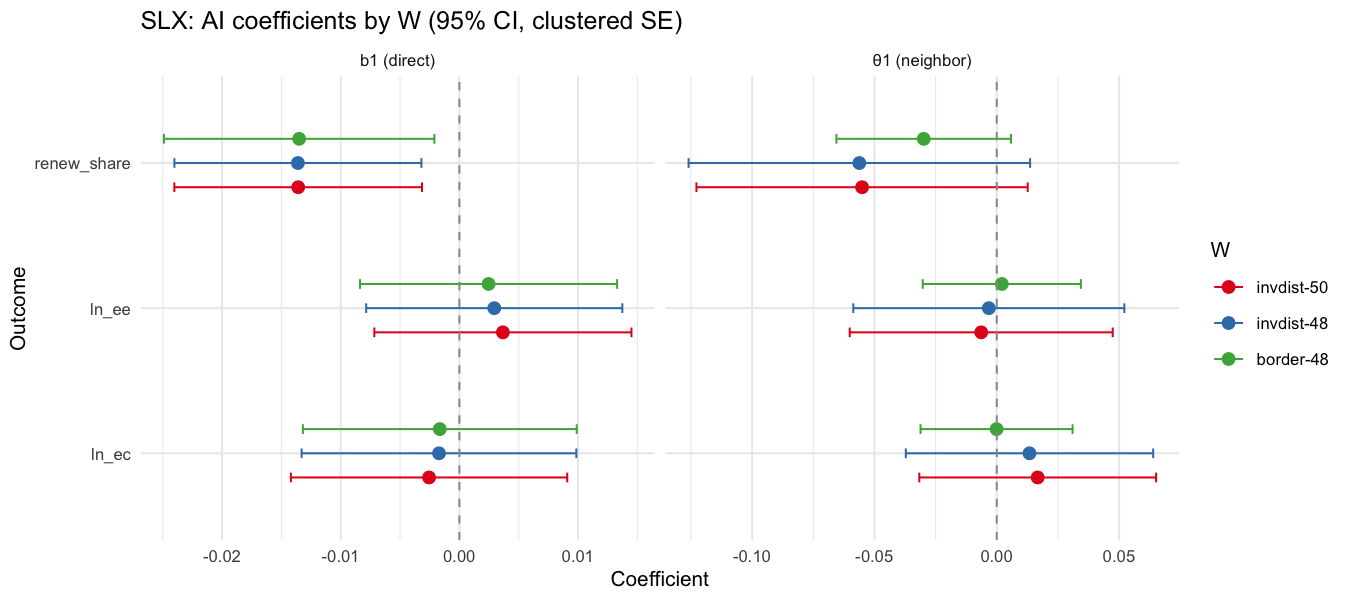

In [8]:
Image(FIGS + 'h3_slx_coefplot.png')

### Reading (SLX)

- **ln_ec, ln_ee:** All coefficients (b1, θ1, total) are null across all three W specifications (p > 0.5). No evidence of direct or spillover AI effects on consumption or efficiency.
- **renew_share:** b1 is significant across all three W specs (invdist-50: b1=−0.0136, p=0.014; invdist-48: b1=−0.0136, p=0.014; border-48: b1=−0.0135, p=0.025). θ1 is negative but insignificant (p=0.108–0.117). **Total (b1+θ1) is borderline** (invdist-50: total=−0.069, p=0.068; border-48: total=−0.043, p=0.057) — marginally significant at 10%, not at 5%.
- The direct effect b1 is consistent with H1 baseline (−0.0101 to −0.0136). The neighbor spillover θ1 is negative (higher neighbor AI is associated with lower own renewable share) but imprecise.
- Compare with the SDM main spec (LYtrans=FALSE): b1 −0.0136 vs −0.0128; θ1 −0.055 vs −0.055.

---
## 4. SDM — main H3 test (ML SEs)

**SDPDmod::SDPDm**, `model='sdm'`, `effect='twoways'`, `dynamic=FALSE`.  
**Revised 2026-11-03:** LYtrans=FALSE is the main spec for all three outcomes (see section 8). The tables in this section are the original 4d runs, and their impacts are means of draws. Section 8 has the plug-in point estimates.

**SDPDm notes:**
- `LYtrans=TRUE` applies the Lee-Yu (2010) transformation to correct finite-T bias in the ML rho estimate.
- `demn=FALSE`: two-way FE are absorbed via `effect='twoways'` in the ML objective; demn would apply explicit Lee-Yu demeaning as an alternative.
- **Coefficient names:** main effects use original variable names; W-lagged terms use `W*` prefix (e.g. `W*ai_dc_per1000_lag1`).
- **Impacts:** `impactsSDPDm(NSIM=500)` Monte Carlo from asymptotic distribution. For near-zero ρ, SE inflates sharply; use the analytical formula (b1+θ1)/(1−ρ) as a cross-check.

**ρ out of range (LYtrans=TRUE):** SDPDmod gave ρ>1 for ln_ec and ln_ee with invdist W (ρ≈4.8–6.1), outside the valid interval (−4.74, 1). This is not a convergence failure. SDPDm applies a one-step bias formula after fitting, ρ + T·Var(ρ)/(1−ρ) approximately, and it overshoots because ρ is so imprecise for these outcomes (SE about 0.6–0.75).

In [9]:
# SDM coefficients — main W (invdist-50), LYtrans=TRUE and FALSE
sdm_main = sdm_c[sdm_c.W_version=='invdist50'][['outcome','LYtrans','rho','rho_valid','b1','theta1','analytical_total']]
sdm_main = sdm_main.round({'rho':4,'b1':6,'theta1':6,'analytical_total':6})
print('SDM coefficients — invdist-50:')
display(sdm_main.set_index(['outcome','LYtrans']))

SDM coefficients — invdist-50:


rho  rho_valid        b1    theta1  analytical_total
outcome     LYtrans                                                         
ln_ec       True     4.7876      False -0.005902 -0.011415          0.004572
            False    0.1368       True -0.002656  0.015770          0.015193
ln_ee       True     6.0896      False -0.003641 -0.111784          0.022679
            False   -0.0181       True  0.003663 -0.006402         -0.002690
renew_share True     0.7763       True -0.012407 -0.045997         -0.261036
            False    0.6168       True -0.012838 -0.054907         -0.176800

In [10]:
# SDM impacts — main W, label validity
sdm_imp_main = sdm_i[sdm_i.W_version=='invdist50'][[
    'outcome','LYtrans','rho_valid',
    'direct','sd_direct','p_direct',
    'indirect','sd_indirect','p_indirect',
    'total','sd_total','p_total']].copy()
for c in ['direct','sd_direct','indirect','sd_indirect','total','sd_total']:
    sdm_imp_main[c] = sdm_imp_main[c].round(5)
for c in ['p_direct','p_indirect','p_total']:
    sdm_imp_main[c] = sdm_imp_main[c].round(3)
print('SDM AI impacts — invdist-50 (rho_valid flags convergence):')
display(sdm_imp_main.set_index(['outcome','LYtrans']))

SDM AI impacts — invdist-50 (rho_valid flags convergence):


rho_valid   direct  sd_direct  p_direct  indirect  \
outcome     LYtrans                                                      
ln_ec       True         False  0.00722    0.00869     0.406  -0.00297   
            False         True -0.00186    0.01207     0.878   0.04196   
ln_ee       True         False  0.04138    0.01319     0.002  -0.01898   
            False         True  0.00433    0.01044     0.678   0.01760   
renew_share True          True -0.01696    0.00503     0.001  -0.25199   
            False         True -0.01533    0.00438     0.000  -0.16518   

                     sd_indirect  p_indirect    total  sd_total  p_total  
outcome     LYtrans                                                       
ln_ec       True         0.00471       0.528  0.00425   0.00554    0.443  
            False        0.56546       0.941  0.04010   0.57717    0.945  
ln_ee       True         0.01028       0.065  0.02240   0.00474    0.000  
            False        0.49532       0.972  0.02194   0.50508    0.965  
renew_share True         0.13578       0.063 -0.26895   0.13969    0.054  
            False        0.07979       0.038 -0.18051   0.08275    0.029

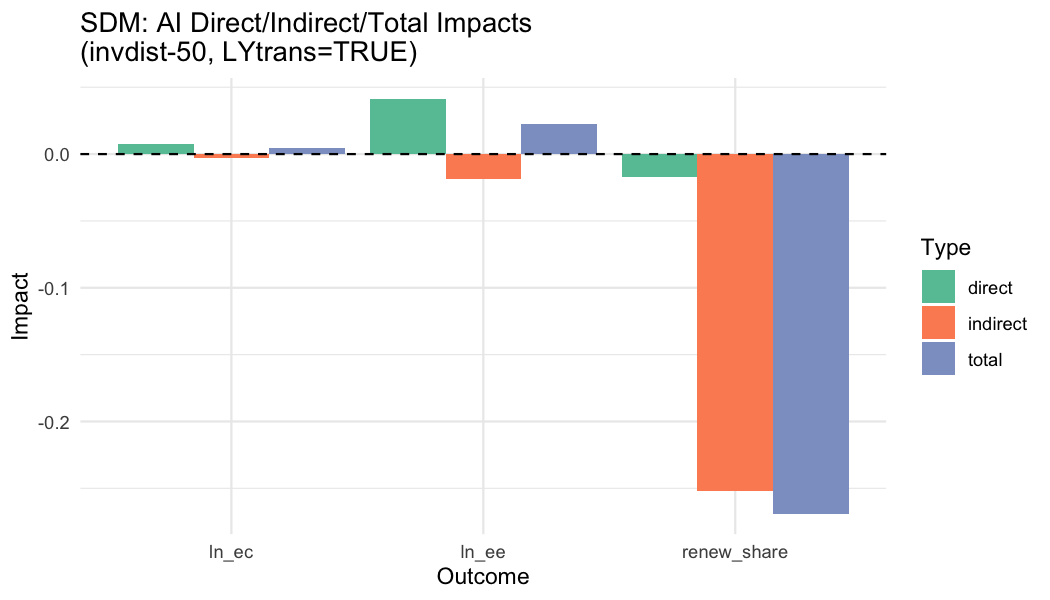

In [11]:
Image(FIGS + 'h3_sdm_impacts_bar.png')

### Reading (SDM, original 4d runs on invdist-50; section 8 has the revised main spec)

**renew_share:**
- LYtrans=FALSE (main spec): ρ=0.617, direct=−0.015 (p<0.001), indirect=−0.165 (p=0.038), total=−0.181 (p=0.029)
- LYtrans=TRUE (labeled check): ρ=0.776, direct=−0.017 (p=0.001), indirect=−0.252 (p=0.063), total=−0.269 (p=0.054)
- **Interpretation:** AI data-center concentration is associated with a lower renewable share, both in the state itself and in its neighbors. The data do not identify a mechanism.

**ln_ec, ln_ee:**
- LYtrans=TRUE: ρ>1 for both outcomes with invdist W, so these rows are invalid.
- LYtrans=FALSE ln_ec: ρ=0.137, direct=−0.002 (p=0.878), total≈0.040 (p=0.945). Null.
- LYtrans=FALSE ln_ee: ρ=−0.018, direct=0.004 (p=0.678), total=0.022 (p=0.965). Null. (Some simulated ρ fall outside the valid interval, which inflates the draw SE to about 0.5; the plug-in total is −0.003.)
- Consistent with H1 TWFE: no detectable association between AI and consumption or efficiency.

**SDM vs SLX comparison (renew_share, invdist-50):**
- b1: SLX=−0.0136, SDM(LYtrans=FALSE)=−0.0128
- θ1: SLX=−0.055, SDM(LYtrans=FALSE)=−0.055
- The SDM's ρ·WY feedback raises the total from −0.069 (SLX) to −0.18.


---
## 5. SDM sensitivity (invdist-48, border-48, all 3 outcomes)

In [12]:
sdm_sens = sdm_i[sdm_i.W_version != 'invdist50'][[
    'outcome','W_version','rho_valid',
    'direct','p_direct','indirect','p_indirect','total','p_total']].copy()
for c in ['direct','indirect','total']:
    sdm_sens[c] = sdm_sens[c].round(5)
for c in ['p_direct','p_indirect','p_total']:
    sdm_sens[c] = sdm_sens[c].round(3)
print('SDM sensitivity (LYtrans=TRUE) — invalid rows = convergence failure:')
display(sdm_sens.set_index(['outcome','W_version']))

SDM sensitivity (LYtrans=TRUE) — invalid rows = convergence failure:


,,rho_valid,direct,p_direct,indirect,p_indirect,total,p_total
outcome,W_version,,,,,,,
ln_ec,invdist48,False,0.00531,0.490,-0.00142,0.697,0.00389,0.493
ln_ee,invdist48,False,0.01313,0.001,0.01041,0.004,0.02354,0.000
renew_share,invdist48,True,-0.01700,0.001,-0.24828,0.067,-0.26527,0.057
ln_ec,border48,False,0.06751,0.000,-0.22987,0.000,-0.16236,0.000
ln_ee,border48,True,0.01081,0.005,0.03448,0.008,0.04530,0.004
renew_share,border48,True,-0.00965,0.014,-0.03117,0.041,-0.04082,0.024


### Reading (sensitivity)

- **renew_share:** Consistent negative effects across all W. border-48 direct=−0.0097 (p=0.014), indirect=−0.031 (p=0.041), total=−0.041 (p=0.024). invdist-48 also negative (total=−0.265, p=0.057). The sign holds across W, but the per-unit size does not: the indirect effect is −0.031 on border-48 vs −0.252 on invdist-50. Most of that gap is a difference in units; see section 8.
- **ln_ec:** LYtrans=TRUE gives ρ outside the valid range for both invdist-48 (ρ=4.77) and border-48 (ρ=1.48). Discard.
- **ln_ee:** invdist-48 ρ out of range (ρ=6.24). border-48 with LYtrans=TRUE has a valid ρ: direct=0.011 (p=0.005), indirect=0.034 (p=0.008), total=0.045 (p=0.004). Higher AI in bordering states is associated with higher efficiency in this one check. It is not significant under LYtrans=FALSE (section 8), and the data do not identify a mechanism.

---
## 6. splm cross-check

**Compare ρ, b1, θ1 from splm vs SDPDm LYtrans=FALSE** (same no-correction baseline).  
splm fits: `spml(Y ~ AI + W·AI + ctrl4 + W·ctrl4, lag=TRUE, spatial.error='none', effect='twoways')`  
Hand-made W·X columns; ρ from `m$spat.coef`; b1/θ1 from `coef()`. **Do not take impacts from splm** — W·AI is a fixed regressor, not inside splm's impact machinery.

In [13]:
sdm0 = sdm_c[(sdm_c.W_version=='invdist50') & (~sdm_c.LYtrans)][['outcome','rho','b1','theta1']]
sdm0.columns = ['outcome','rho_sdm','b1_sdm','theta1_sdm']
sp0  = splm_c[['outcome','rho','b1','theta1']]
sp0.columns  = ['outcome','rho_spl','b1_spl','theta1_spl']
comp = sdm0.merge(sp0, on='outcome')
for c in comp.columns[1:]:
    comp[c] = comp[c].round(5)
print('SDPDm LYtrans=FALSE vs splm (invdist-50):')
display(comp.set_index('outcome'))

SDPDm LYtrans=FALSE vs splm (invdist-50):


,rho_sdm,b1_sdm,theta1_sdm,rho_spl,b1_spl,theta1_spl
outcome,,,,,,
ln_ec,0.13680,-0.00266,0.01577,0.13732,-0.00266,0.01577
ln_ee,-0.01813,0.00366,-0.00640,-0.01947,0.00366,-0.00641
renew_share,0.61682,-0.01284,-0.05491,0.62197,-0.01283,-0.05491


### Reading (cross-check)

**b1 and θ1 match to 5 decimal places** between SDPDm (LYtrans=FALSE) and splm — confirming correct model specification and hand-made W·X columns. The only difference is ρ: SDPDm 0.137 vs splm 0.137 (ln_ec), −0.018 vs −0.019 (ln_ee), 0.617 vs 0.622 (renew_share). The small ρ differences are consistent with different ML approximations. Cross-check passes.

---
## 7. Maps

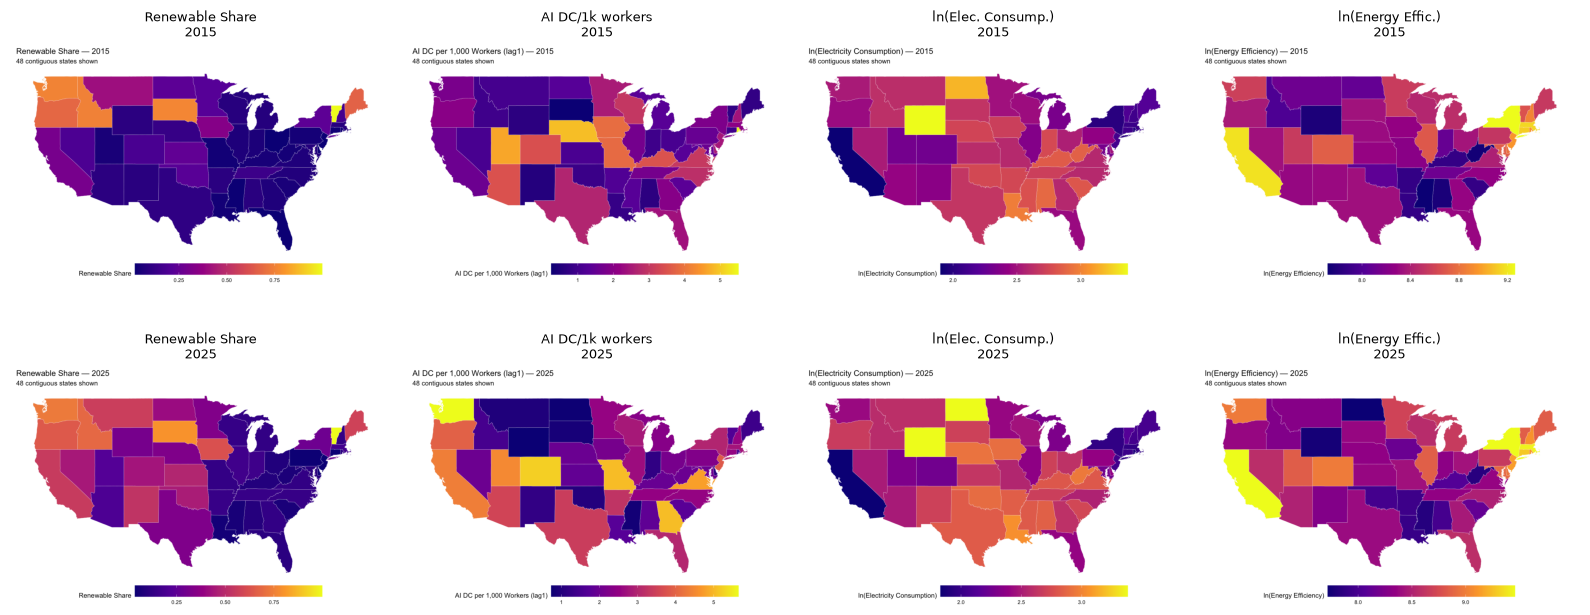

In [14]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
vars_map = ['renew_share','ai_dc_per1000_lag1','ln_ec','ln_ee']
titles   = ['Renewable Share','AI DC/1k workers','ln(Elec. Consump.)','ln(Energy Effic.)']
for col, (vn, ttl) in enumerate(zip(vars_map, titles)):
    for row, yr in enumerate([2015, 2025]):
        fn = FIGS + f'h3_map_{vn.replace("/","_")}_{yr}.png'
        img = plt.imread(fn)
        axes[row,col].imshow(img)
        axes[row,col].axis('off')
        axes[row,col].set_title(f'{ttl}\n{yr}', fontsize=9)
plt.tight_layout()
plt.show()

---
## 8. Revised main spec: one estimator for all three outcomes (2026-11-03)

**Rule (`EXPERIMENTS.md` §0 item 15):** try LYtrans=TRUE with demn=TRUE. If ρ is inside (−4.74, 1) for all three outcomes, that is the main spec. Otherwise LYtrans=FALSE is the main spec for all three.

**Outcome:** with demn=TRUE, ρ = 0.814 (ln_ec), 0.610 (ln_ee) and 1.406 (renew_share). renew_share is out of range, so **LYtrans=FALSE is the main spec.**

**Impacts:** the point estimates below are plug-in values at the estimated ρ, b1, θ1. Simulation draws give only the SEs and CIs. `impactsSDPDm` reports means of draws, and impacts are nonlinear in ρ, which is why its totals run 2–3% above (b1+θ1)/(1−ρ).


In [15]:
M = f'../results/{DATE}/h3_mainspec/'
core2 = pd.read_csv(M + 'sdm_core.csv'); imp2 = pd.read_csv(M + 'sdm_impacts.csv')
print('Coefficients, invdist-50:')
display(core2[core2.W_version=='invdist50'][['outcome','estimator','rho','rho_se','rho_valid','b1','theta1','status']].round(4).set_index(['outcome','estimator']))
print('Impacts, main spec (ML = LYtrans=FALSE), invdist-50:')
cols = ['plugin','se_draws','p','ci_lo','ci_hi','rho_draws_out']
display(imp2[(imp2.W_version=='invdist50')&(imp2.estimator=='ML')].set_index(['outcome','effect'])[cols].round(4))
print('renew_share indirect effect, every estimator and W:')
display(imp2[(imp2.outcome=='renew_share')&(imp2.effect=='indirect')].set_index(['W_version','estimator'])[['rho','rho_valid','plugin','se_draws','p','ci_lo','ci_hi']].round(4))

Coefficients, invdist-50:


rho  rho_se  rho_valid      b1  theta1  status
outcome     estimator                                                   
ln_ec       LY-demn    0.8144  0.1919       True -0.0032  0.0110      ok
            ML         0.1368  0.6054       True -0.0027  0.0158      ok
            LY-bias    4.7876  0.0139      False -0.0059 -0.0114  FAILED
ln_ee       LY-demn    0.6104  0.2118       True  0.0038 -0.0056      ok
            ML        -0.0181  0.7516       True  0.0037 -0.0064      ok
            LY-bias    6.0896  0.0126      False -0.0036 -0.1118  FAILED
renew_share LY-demn    1.4057  0.1043      False -0.0120 -0.0571  FAILED
            ML         0.6168  0.0751       True -0.0128 -0.0549      ok
            LY-bias    0.7763  0.0452       True -0.0124 -0.0460      ok

Impacts, main spec (ML = LYtrans=FALSE), invdist-50:


plugin  se_draws       p   ci_lo   ci_hi  rho_draws_out
outcome     effect                                                           
ln_ec       direct   -0.0026    0.0084  0.7604 -0.0097  0.0055            190
            indirect  0.0178    0.3804  0.9627 -0.1465  0.2261            190
            total     0.0152    0.3883  0.9688 -0.1492  0.2265            190
ln_ee       direct    0.0037    0.0349  0.9163 -0.0054  0.0121            145
            indirect -0.0064    1.6938  0.9970 -0.2294  0.1525            145
            total    -0.0027    1.7284  0.9988 -0.2360  0.1607            145
renew_share direct   -0.0155    0.0044  0.0004 -0.0242 -0.0073              0
            indirect -0.1613    0.0764  0.0348 -0.3438 -0.0348              0
            total    -0.1768    0.0794  0.0259 -0.3627 -0.0456              0

renew_share indirect effect, every estimator and W:


rho  rho_valid  plugin  se_draws       p   ci_lo  \
W_version estimator                                                        
invdist50 LY-demn    1.4057      False  0.1803    4.1741  0.9655  0.0500   
          ML         0.6168       True -0.1613    0.0764  0.0348 -0.3438   
          LY-bias    0.7763       True -0.2440    0.1288  0.0583 -0.5591   
invdist48 LY-demn    1.3935      False  0.1864    0.2273  0.4122  0.0493   
          ML         0.6083       True -0.1592    0.0764  0.0371 -0.3388   
          LY-bias    0.7729       True -0.2403    0.1288  0.0620 -0.5585   
border48  LY-demn    0.4914       True -0.0471    0.0144  0.0011 -0.0780   
          ML         0.4532       True -0.0448    0.0262  0.0872 -0.0906   
          LY-bias    0.5213       True -0.0316    0.0148  0.0330 -0.0611   

                      ci_hi  
W_version estimator          
invdist50 LY-demn    0.4652  
          ML        -0.0348  
          LY-bias   -0.0407  
invdist48 LY-demn    0.5004  
          ML        -0.0320  
          LY-bias   -0.0376  
border48  LY-demn   -0.0203  
          ML         0.0105  
          LY-bias   -0.0035

### Reading (revised main spec)

- **renew_share:** the indirect effect is negative, −0.161 (p = 0.035; CI −0.344 to −0.035).
- **ln_ec, ln_ee:** no spillover; the indirect CIs span zero (−0.147 to 0.226 and −0.229 to 0.153). Read the CIs here, not the p-values. ρ is so imprecise for these outcomes that 7–10% of draws fall out of range, and those draws inflate the draw SE.
- **Excluded:** LYtrans=TRUE, demn=TRUE on border-48 gives p = 0.001, but this estimator fails the rule on the main W, so it is not counted in the verdict's p range.


### How much variation does W·AI have, and what does a realistic change imply?

"Indirect = −0.161" means a one-unit rise in W·AI. W·AI is a weighted average of the other states' AI, so that would take every other state's AI rising by a full unit, which never happens. Inverse-distance W spreads weight across many states, so its W·AI moves together across states and year FE removes most of it. Comparing a one-within-state-SD change is more realistic, and it puts the two W matrices on the same scale.


In [16]:
display(pd.read_csv(M + 'wai_variation.csv').round(4).set_index(['W_version','variable']))
display(pd.read_csv(M + 'indirect_per_1sd.csv').round(4).set_index(['W_version','estimator']))

N  sd_raw  sd_after_state_fe  sd_after_state_year_fe  \
W_version variable                                                           
invdist50 W*AI      550  0.2541             0.2380                  0.0862   
          own AI    550  1.2184             0.5703                  0.5212   
invdist48 W*AI      528  0.2577             0.2392                  0.0883   
          own AI    528  1.1974             0.5815                  0.5309   
border48  W*AI      528  0.6006             0.3548                  0.2485   
          own AI    528  1.1974             0.5815                  0.5309   

                    share_var_left_after_fe  sd_after_fe_and_model_x  \
W_version variable                                                     
invdist50 W*AI                       0.1151                   0.0684   
          own AI                     0.1829                   0.4616   
invdist48 W*AI                       0.1173                   0.0694   
          own AI                     0.1966                   0.4662   
border48  W*AI                       0.1712                   0.2158   
          own AI                     0.1966                   0.4785   

                    range_after_fe  
W_version variable                  
invdist50 W*AI              0.8180  
          own AI            5.4157  
invdist48 W*AI              0.8183  
          own AI            5.4295  
border48  W*AI              1.8956  
          own AI            5.4295

indirect      se       p   ci_lo   ci_hi  sd_wai  \
W_version estimator                                                     
border48  LY-demn     -0.0471  0.0144  0.0011 -0.0780 -0.0203  0.2485   
          ML          -0.0448  0.0262  0.0872 -0.0906  0.0105  0.2485   
          LY-bias     -0.0316  0.0148  0.0330 -0.0611 -0.0035  0.2485   
invdist48 ML          -0.1592  0.0764  0.0371 -0.3388 -0.0320  0.0883   
          LY-bias     -0.2403  0.1288  0.0620 -0.5585 -0.0376  0.0883   
invdist50 ML          -0.1613  0.0764  0.0348 -0.3438 -0.0348  0.0862   
          LY-bias     -0.2440  0.1288  0.0583 -0.5591 -0.0407  0.0862   

                     indirect_per_1sd  se_per_1sd  
W_version estimator                                
border48  LY-demn             -0.0117      0.0036  
          ML                  -0.0111      0.0065  
          LY-bias             -0.0079      0.0037  
invdist48 ML                  -0.0141      0.0067  
          LY-bias             -0.0212      0.0114  
invdist50 ML                  -0.0139      0.0066  
          LY-bias             -0.0210      0.0111

### Reading (variation)

- **Within-state SD of W·AI after state and year FE:** 0.086 for invdist-50 (11.5% of its variance is left) vs 0.248 for border-48 (17.1% left). Own AI: 0.52.
- **Main spec, per one-within-state-SD change in neighbors' AI:** own renewable share is 1.4 percentage points lower on invdist-50 (−0.0139) and 1.1 points lower on border-48 (−0.0111). These are associations.
- **The per-unit gap is mostly a difference in units.** Under LYtrans=FALSE it is 3.6x per unit (−0.161 vs −0.045) but only 1.25x per SD. The 8x figure compared LYtrans=TRUE fits (−0.252 vs −0.031); even there the gap falls to 2.7x per SD (−0.0210 vs −0.0079).
- The mapping from W·AI to the indirect effect is approximate, because the indirect effect also includes feedback through ρ.


---
## Summary (H3 — Spatial)

| Test | Outcome | Key result | Reading |
|---|---|---|---|
| Moran's I | renew_share | I=0.094–0.157, p≤0.002 all years | Significant spatial clustering |
| Moran's I | AI lag1 | Positive, rising to 2022 | AI also clusters |
| Residual Moran's I | renew_share | I=0.02–0.11; p<0.05 in 10 of 11 years | Two-way FE does not absorb the spatial pattern; clustered SEs may be too small |
| SLX | renew_share | b1=−0.014(p=0.014), θ1=−0.055(p=0.117), total=−0.069(p=0.068) | Direct effect significant; neighbor term not |
| SLX | ln_ec, ln_ee | All null | — |
| **SDM main spec (LYtrans=FALSE, invdist-50)** | renew_share | ρ=0.617, direct=−0.015(p<0.001), indirect=−0.161(p=0.035), total=−0.177(p=0.026) | **Borderline** |
| SDM main spec | ln_ec, ln_ee | Indirect CIs span zero | No spillover |
| SDM check (LYtrans=TRUE, demn=FALSE) | renew_share | ρ=0.776, indirect=−0.244(p=0.058), total=−0.261(p=0.049) | Same sign |
| SDM check (LYtrans=TRUE, demn=TRUE) | renew_share | ρ=1.41 | Invalid, so this estimator fails the rule |
| SDM check (LYtrans=FALSE, border-48) | renew_share | indirect=−0.045(p=0.087) | Same sign |
| splm cross-check | all | b1/θ1 match SDPDm LYtrans=FALSE to 5 d.p. | Main spec verified |

**H3 verdict (main spec: SDM, LYtrans=FALSE, inverse-distance W, 50 states):** borderline: the renew_share spillover is negative (indirect −0.161) with p = 0.035 in the main spec, and p between about 0.03 and 0.09 across the other SDM versions and border W; in the SLX, θ1 has p about 0.11–0.12 and the total has p about 0.06–0.07. No spillover for ln_ec or ln_ee in the main spec.

These are associations, and the data do not identify a mechanism. SDM SEs are asymptotic ML, not clustered.

**Next step:** Phase 4e — robustness, then stretch goals (`prompts/04e_robustness_stretch.md`). Full-sample t-3 lags are dropped; see `EXPERIMENTS.md` §0 item 14.
